# Fase 1. Comprensión del problema

**Responsable:** Jorge Elias Builes Chavarria
Equipo 8 · Análisis de Datos · Ingeniería de Sistemas, ITM · 2026-2

## Contexto del dataset

Trabajamos con *Video Game Sales*, publicado en Kaggle por Gregory Smith (usuario `gregorut`). Los datos salieron de un scraping al sitio VGChartz y cada fila es un juego en una plataforma específica, o sea que *Grand Theft Auto V* aparece varias veces (PS3, X360, PS4, etc.).

Las ventas están en **millones de unidades vendidas**, no en dinero, y vienen separadas en cuatro regiones: Norteamérica (`NA_Sales`), Europa (`EU_Sales`), Japón (`JP_Sales`) y resto del mundo (`Other_Sales`). `Global_Sales` es el total. Las demás columnas son el ranking, nombre, plataforma, año de lanzamiento, género y publisher (la empresa que distribuye el juego).

Fuente: https://www.kaggle.com/datasets/gregorut/videogamesales

## Problema de negocio

Nos pusimos en el lugar del área de BI de un publisher mediano que tiene que decidir en qué invertir su presupuesto de desarrollo y marketing para los próximos lanzamientos: qué género, para qué plataforma y pensando en qué mercado.

El problema es que la industria de videojuegos es muy riesgosa. Unos pocos títulos se llevan la mayor parte de las ventas y la mayoría vende poco, entonces la idea es mirar el histórico para encontrar patrones que ayuden a bajar ese riesgo.

## Preguntas clave

1. ¿Qué géneros venden más **por título lanzado**? Mirar solo el total puede confundir, porque hay géneros con muchísimos lanzamientos.
2. ¿Las preferencias de género cambian según la región? En particular, ¿Japón se comporta distinto a Norteamérica y Europa?
3. ¿Los juegos que publica el mismo fabricante de la consola (first-party, por ejemplo Nintendo en Wii) venden más que los de terceros?
4. ¿Qué tan concentradas están las ventas en pocos títulos y en pocos publishers?
5. ¿Cómo cambiaron los lanzamientos y las ventas por título a lo largo de los años?

## Primera revisión de los datos

In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
import estilo

estilo.configurar()
pd.set_option("display.float_format", "{:.2f}".format)

df = pd.read_csv(estilo.RAW)
print(df.shape)
df.head()

(16598, 11)


,Rank,Name,Platform,Year,Genre,Publisher,NA_Sales,EU_Sales,JP_Sales,Other_Sales,Global_Sales
0,1,Wii Sports,Wii,2006.00,Sports,Nintendo,41.49,29.02,3.77,8.46,82.74
1,2,Super Mario Bros.,NES,1985.00,Platform,Nintendo,29.08,3.58,6.81,0.77,40.24
2,3,Mario Kart Wii,Wii,2008.00,Racing,Nintendo,15.85,12.88,3.79,3.31,35.82
3,4,Wii Sports Resort,Wii,2009.00,Sports,Nintendo,15.75,11.01,3.28,2.96,33.00
4,5,Pokemon Red/Pokemon Blue,GB,1996.00,Role-Playing,Nintendo,11.27,8.89,10.22,1.00,31.37


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 16598 entries, 0 to 16597
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   Rank          16598 non-null  int64  
 1   Name          16598 non-null  str    
 2   Platform      16598 non-null  str    
 3   Year          16327 non-null  float64
 4   Genre         16598 non-null  str    
 5   Publisher     16540 non-null  str    
 6   NA_Sales      16598 non-null  float64
 7   EU_Sales      16598 non-null  float64
 8   JP_Sales      16598 non-null  float64
 9   Other_Sales   16598 non-null  float64
 10  Global_Sales  16598 non-null  float64
dtypes: float64(6), int64(1), str(4)
memory usage: 1.4 MB


In [3]:
# nulos por columna
nulos = df.isna().sum()
nulos[nulos > 0]

Year         271
Publisher     58
dtype: int64

In [4]:
ventas = ["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales", "Global_Sales"]
df[ventas].describe().T

,count,mean,std,min,25%,50%,75%,max
NA_Sales,16598.00,0.26,0.82,0.00,0.00,0.08,0.24,41.49
EU_Sales,16598.00,0.15,0.51,0.00,0.00,0.02,0.11,29.02
JP_Sales,16598.00,0.08,0.31,0.00,0.00,0.00,0.04,10.22
Other_Sales,16598.00,0.05,0.19,0.00,0.00,0.01,0.04,10.57
Global_Sales,16598.00,0.54,1.56,0.01,0.06,0.17,0.47,82.74


In [5]:
print("Asimetría Global_Sales:", round(df["Global_Sales"].skew(), 2))
print("Curtosis Global_Sales:", round(df["Global_Sales"].kurt(), 2))

# la descripción de Kaggle dice que son juegos con más de 100.000 copias, revisamos
menores = (df["Global_Sales"] < 0.1).sum()
print(f"Registros con menos de 0,1 M: {menores} ({menores / len(df):.1%})")

Asimetría Global_Sales: 17.4
Curtosis Global_Sales: 603.93
Registros con menos de 0,1 M: 5781 (34.8%)


In [6]:
print("Plataformas:", df["Platform"].nunique())
print("Géneros:", df["Genre"].nunique())
print("Publishers:", df["Publisher"].nunique())
print("Años:", int(df["Year"].min()), "a", int(df["Year"].max()))

Plataformas: 31
Géneros: 12
Publishers: 578
Años: 1980 a 2020


In [7]:
# los 10 más vendidos
df.nlargest(10, "Global_Sales")[["Name", "Platform", "Year", "Publisher", "Global_Sales"]]

,Name,Platform,Year,Publisher,Global_Sales
0,Wii Sports,Wii,2006.00,Nintendo,82.74
1,Super Mario Bros.,NES,1985.00,Nintendo,40.24
2,Mario Kart Wii,Wii,2008.00,Nintendo,35.82
3,Wii Sports Resort,Wii,2009.00,Nintendo,33.00
4,Pokemon Red/Pokemon Blue,GB,1996.00,Nintendo,31.37
5,Tetris,GB,1989.00,Nintendo,30.26
6,New Super Mario Bros.,DS,2006.00,Nintendo,30.01
7,Wii Play,Wii,2006.00,Nintendo,29.02
8,New Super Mario Bros. Wii,Wii,2009.00,Nintendo,28.62
9,Duck Hunt,NES,1984.00,Nintendo,28.31


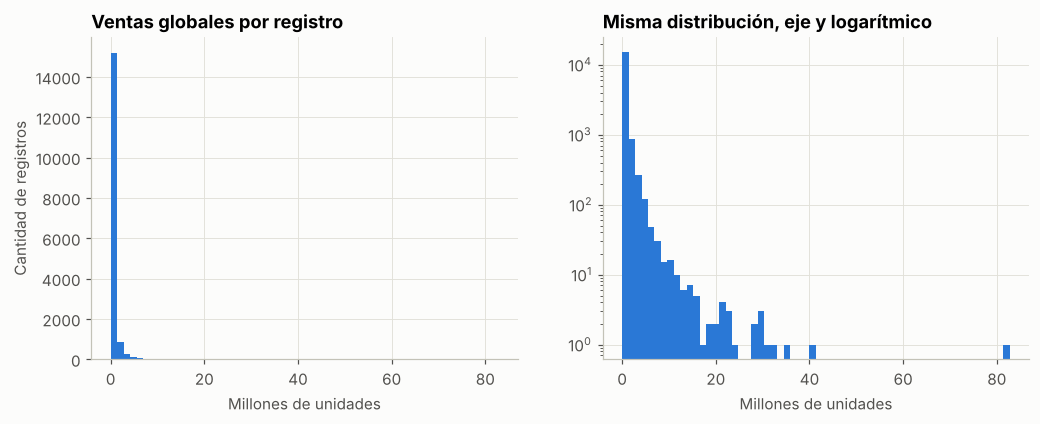

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))

axes[0].hist(df["Global_Sales"], bins=60, color=estilo.AZUL)
axes[0].set_title("Ventas globales por registro")
axes[0].set_xlabel("Millones de unidades")
axes[0].set_ylabel("Cantidad de registros")

axes[1].hist(df["Global_Sales"], bins=60, color=estilo.AZUL, log=True)
axes[1].set_title("Misma distribución, eje y logarítmico")
axes[1].set_xlabel("Millones de unidades")

estilo.guardar(fig, "f1_distribucion_ventas")
plt.show()

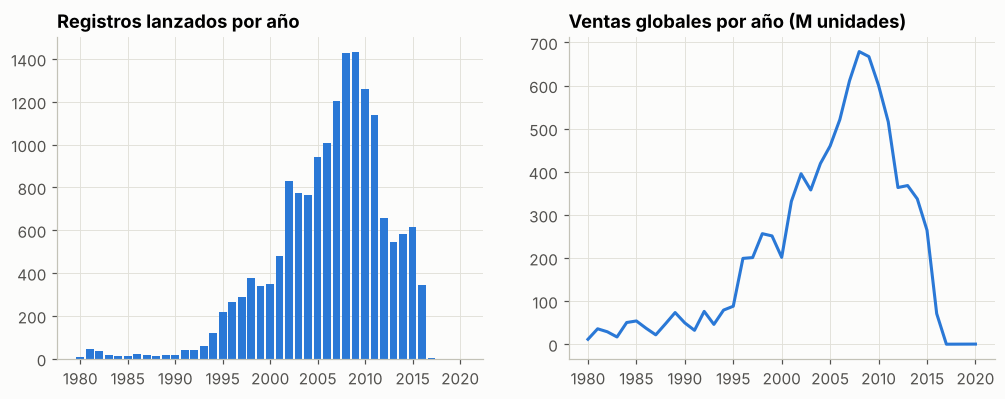

,titulos,ventas
Year,,
2013.00,546,368.11
2014.00,582,337.05
2015.00,614,264.44
2016.00,344,70.93
2017.00,3,0.05
2020.00,1,0.29


In [9]:
por_anio = df.groupby("Year").agg(titulos=("Name", "size"), ventas=("Global_Sales", "sum"))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].bar(por_anio.index, por_anio["titulos"], color=estilo.AZUL, width=0.8)
axes[0].set_title("Registros lanzados por año")
axes[1].plot(por_anio.index, por_anio["ventas"], color=estilo.AZUL, lw=2)
axes[1].set_title("Ventas globales por año (M unidades)")
estilo.guardar(fig, "f1_evolucion_anual")
plt.show()

por_anio.tail(6)

In [10]:
# total por región
reg = df[["NA_Sales", "EU_Sales", "JP_Sales", "Other_Sales"]].sum().rename(estilo.REGIONES)
(reg / reg.sum() * 100).round(1)

Norteamérica   49.30
Europa         27.30
Japón          14.50
Otros           8.90
dtype: float64

In [11]:
# vista rápida por género: total vs mediana por título
resumen_genero = (df.groupby("Genre")["Global_Sales"]
                    .agg(titulos="size", total="sum", mediana="median")
                    .sort_values("total", ascending=False))
resumen_genero

,titulos,total,mediana
Genre,,,
Action,3316,1751.18,0.19
Sports,2346,1330.93,0.22
Shooter,1310,1037.37,0.23
Role-Playing,1488,927.37,0.18
Platform,886,831.37,0.28
Misc,1739,809.96,0.16
Racing,1249,732.04,0.19
Fighting,848,448.91,0.21
Simulation,867,392.20,0.16


## Lo que nos deja esta primera mirada

- Son 16.598 registros y 11 columnas. Hay 271 registros sin año y 58 sin publisher, que se tratan en la Fase 3.
- Las ventas son muy asimétricas (asimetría cercana a 17). La media global es 0,54 M pero la mediana es apenas 0,17 M. Esto ya nos dice que para comparar grupos más adelante no conviene usar pruebas que asuman normalidad.
- La descripción de Kaggle habla de juegos con más de 100.000 copias, pero el 35 % de los registros está por debajo de 0,1 M (el mínimo es 0,01 M). Lo dejamos anotado como limitación.
- Los 10 juegos más vendidos son todos de Nintendo y casi todos en sus propias consolas (Wii, NES, GB, DS). Eso fue lo que nos llevó a la pregunta 3.
- Los años 2017 y 2020 tienen 3 y 1 registro, y 2016 tiene muchos menos que 2015. Todo indica que el scraping se hizo en 2016 y esos años están incompletos.
- Acción es el género que más vende en total, pero cuando se mira la mediana por título queda en la mitad de la tabla. Plataformas y Disparos venden más por juego. Esto se valida formalmente en la Fase 2.
- Norteamérica pesa casi la mitad de las ventas.